# Conference evidence pack — GitHub + literature-gap validation

**For a separate Google Colab account.** The notebook clones the public GitHub repository directly. No access to the user's Google Drive is needed.

**Tonight's goal:** verify existing evidence, create reproducible tables/figures, and export a conference evidence ZIP. It does not train models or invent new results.


In [1]:
import pathlib, subprocess, json, sys, os
REPO_URL="https://github.com/Karthik6-cpu/cartoonization-robustness-study.git"
BRANCH="research/cafr-net-phase-iv"
REPO=pathlib.Path("/content/cartoonization-robustness-study")
if not REPO.exists():
    subprocess.run(["git","clone","--depth","1","--branch",BRANCH,REPO_URL,str(REPO)],check=True)
else:
    subprocess.run(["git","-C",str(REPO),"fetch","origin",BRANCH],check=True)
    subprocess.run(["git","-C",str(REPO),"checkout",BRANCH],check=True)
    subprocess.run(["git","-C",str(REPO),"pull","--ff-only","origin",BRANCH],check=True)
SHA=subprocess.check_output(["git","-C",str(REPO),"rev-parse","HEAD"],text=True).strip()
print("Pinned commit:",SHA)


Pinned commit: cd5216c5b14325cfae9e3de2f56e0fea428911ab


In [2]:
%pip -q install pandas numpy matplotlib scipy openpyxl


In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, shutil, zipfile
BASE=REPO/"research"/"CAFRNet_v2"/"results"/"imagenette"
seeds=pd.read_csv(BASE/"CAFRNet_Three_Seed_Results.csv")
saved=pd.read_csv(BASE/"CAFRNet_Three_Seed_Summary.csv")
abl=pd.read_csv(BASE/"CAFRNet_Final_Ablation_Results.csv")
comparison=pd.read_csv(BASE/"model_comparison_metrics.csv")
display(seeds); display(saved)


,Seed,Condition,Accuracy,Macro_F1
0,Seed_42,animegan2,99.363057,99.362700
1,Seed_42,opencv,95.159236,95.221685
2,Seed_42,original,99.796178,99.796772
3,Seed_42,stable_diffusion,95.414013,95.446872
4,Seed_123,animegan2,98.343949,98.327046
5,Seed_123,opencv,88.738854,88.602902
6,Seed_123,original,99.796178,99.797681
7,Seed_123,stable_diffusion,94.471338,94.443523
8,Seed_2026,animegan2,98.496815,98.483669
9,Seed_2026,opencv,87.312102,87.770544


,Condition,Accuracy_Mean,Accuracy_Std,Accuracy_Min,Accuracy_Max,MacroF1_Mean,MacroF1_Std
0,animegan2,98.734607,0.549595,98.343949,99.363057,98.724472,0.558242
1,opencv,90.403397,4.180001,87.312102,95.159236,90.531710,4.082904
2,original,99.770701,0.044129,99.719745,99.796178,99.770365,0.046528
3,stable_diffusion,94.726115,0.602374,94.292994,95.414013,94.722470,0.632850


## Recompute the three-seed summary from committed per-seed results

In [4]:
recalc=(seeds.groupby("Condition").agg(
    Accuracy_Mean=("Accuracy","mean"), Accuracy_Std=("Accuracy","std"),
    MacroF1_Mean=("Macro_F1","mean"), MacroF1_Std=("Macro_F1","std"),
    Number_of_Seeds=("Seed","nunique")).reset_index())
saved2=saved.copy(); saved2["Condition"]=saved2["Condition"].str.lower()
check=recalc.merge(saved2,on="Condition",suffixes=("_recomputed","_saved"))
for col in ["Accuracy_Mean","Accuracy_Std","MacroF1_Mean","MacroF1_Std"]:
    check[col+"_absolute_error"]=(check[col+"_recomputed"]-check[col+"_saved"]).abs()
display(check)
print("Max absolute difference:",check.filter(like="absolute_error").to_numpy().max())


,Condition,Accuracy_Mean_recomputed,Accuracy_Std_recomputed,MacroF1_Mean_recomputed,MacroF1_Std_recomputed,Number_of_Seeds,Accuracy_Mean_saved,Accuracy_Std_saved,Accuracy_Min,Accuracy_Max,MacroF1_Mean_saved,MacroF1_Std_saved,Accuracy_Mean_absolute_error,Accuracy_Std_absolute_error,MacroF1_Mean_absolute_error,MacroF1_Std_absolute_error
0,animegan2,98.734607,0.549595,98.724472,0.558242,3,98.734607,0.549595,98.343949,99.363057,98.724472,0.558242,1.421085e-14,9.880985e-15,0.0,9.880985e-15
1,opencv,90.403397,4.180001,90.531710,4.082904,3,90.403397,4.180001,87.312102,95.159236,90.531710,4.082904,0.000000e+00,0.000000e+00,0.0,0.000000e+00
2,original,99.770701,0.044129,99.770365,0.046528,3,99.770701,0.044129,99.719745,99.796178,99.770365,0.046528,0.000000e+00,9.020562e-17,0.0,4.107825e-15
3,stable_diffusion,94.726115,0.602374,94.722470,0.632850,3,94.726115,0.602374,94.292994,95.414013,94.722470,0.632850,0.000000e+00,6.439294e-15,0.0,2.775558e-15


Max absolute difference: 1.4210854715202004e-14


## Generate figures from the committed results

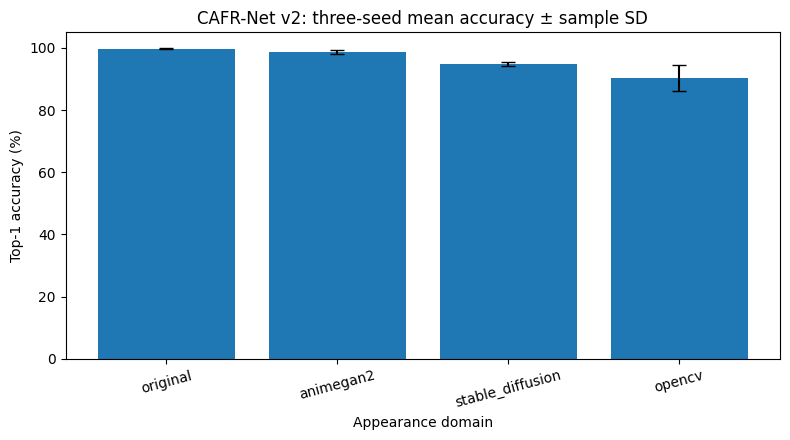

In [5]:
plot=recalc.sort_values("Accuracy_Mean",ascending=False)
plt.figure(figsize=(8,4.5))
plt.bar(plot["Condition"],plot["Accuracy_Mean"],yerr=plot["Accuracy_Std"],capsize=5)
plt.ylabel("Top-1 accuracy (%)"); plt.xlabel("Appearance domain")
plt.title("CAFR-Net v2: three-seed mean accuracy ± sample SD")
plt.ylim(0,105); plt.xticks(rotation=15); plt.tight_layout()
fig="/content/CAFR_three_seed_accuracy.png"
plt.savefig(fig,dpi=220); plt.show()


## Explicitly flag the conflicting CAFR–ConvNeXt comparison file

In [6]:
seed42=float(seeds[(seeds["Seed"].astype(str).str.contains("42"))&(seeds["Condition"].str.lower()=="opencv")]["Accuracy"].iloc[0])
mean=float(recalc[recalc["Condition"].str.lower()=="opencv"]["Accuracy_Mean"].iloc[0])
csv_cafr=float(comparison.loc[comparison.condition.str.lower()=="opencv","CAFR_accuracy"].iloc[0])*100
csv_conv=float(comparison.loc[comparison.condition.str.lower()=="opencv","ConvNeXt_accuracy"].iloc[0])*100
print({"CAFR_seed42_opencv":seed42,"CAFR_three_seed_mean_opencv":mean,
       "comparison_csv_CAFR_opencv":csv_cafr,"comparison_csv_ConvNeXt_opencv":csv_conv})
print("Do not use the comparison CSV as a definitive head-to-head until run/checkpoint provenance is reconciled.")


{'CAFR_seed42_opencv': 95.1592356687898, 'CAFR_three_seed_mean_opencv': 90.40339702760086, 'comparison_csv_CAFR_opencv': 78.11464968152866, 'comparison_csv_ConvNeXt_opencv': 83.23566878980891}
Do not use the comparison CSV as a definitive head-to-head until run/checkpoint provenance is reconciled.


## Literature-gap matrix for the supervisor

In [7]:
literature_gap=pd.DataFrame([
["ImageNet-C / ImageNet-P (Hendrycks & Dietterich, ICLR 2019)","Standardized common-corruption/perturbation evaluation","Does not isolate cartoonization as a semantic-preserving appearance domain","Matched cartoonizer domains + JPEG interactions; keep corruption families distinct"],
["Many Faces of Robustness (Hendrycks et al., ICCV 2021)","OOD robustness is multidimensional; IID accuracy is insufficient","Broad benchmark does not answer this exact matched cartoonizer/JPEG question","Per-domain and paired analysis, with uncertainty"],
["Rethinking Robustness of Image Style Transfer (Wang et al., CVPR 2021)","Style-transfer behaviour depends on feature-extractor architecture","Focus is style-transfer behaviour, not downstream classifier recognition","Measure recognition separately from generation quality"],
["StyDeSty (Liu et al., ICML 2024)","Coherent stylization/destylization for single-domain generalization","Different method/problem framing from matched multi-cartoonizer/JPEG assessment","Position CAFR cautiously; do not claim superiority without matched baseline"],
["GAN-Based Multi-Style Photo Cartoonization (Shu et al., IEEE TVCG 2022)","Advances cartoon image generation","Generation quality is not downstream classification robustness","Evaluate classifier accuracy/F1/calibration across generated domains"],
["Rusak et al. (ECCV 2020)","Noise training can generalize to unseen corruptions","Does not establish generalization to strong stylization shift","Separate low-level corruption robustness from cartoonization shift"]
],columns=["Prior work","Established contribution","Relevant scope limitation","Our response"])
display(literature_gap)


,Prior work,Established contribution,Relevant scope limitation,Our response
0,ImageNet-C / ImageNet-P (Hendrycks & Dietteric...,Standardized common-corruption/perturbation ev...,Does not isolate cartoonization as a semantic-...,Matched cartoonizer domains + JPEG interaction...
1,"Many Faces of Robustness (Hendrycks et al., IC...",OOD robustness is multidimensional; IID accura...,Broad benchmark does not answer this exact mat...,"Per-domain and paired analysis, with uncertainty"
2,Rethinking Robustness of Image Style Transfer ...,Style-transfer behaviour depends on feature-ex...,"Focus is style-transfer behaviour, not downstr...",Measure recognition separately from generation...
3,"StyDeSty (Liu et al., ICML 2024)",Coherent stylization/destylization for single-...,Different method/problem framing from matched ...,Position CAFR cautiously; do not claim superio...
4,GAN-Based Multi-Style Photo Cartoonization (Sh...,Advances cartoon image generation,Generation quality is not downstream classific...,Evaluate classifier accuracy/F1/calibration ac...
5,Rusak et al. (ECCV 2020),Noise training can generalize to unseen corrup...,Does not establish generalization to strong st...,Separate low-level corruption robustness from ...


## Export a compact evidence pack

In [8]:
PACK=pathlib.Path("/content/Conference_Evidence_Pack"); PACK.mkdir(exist_ok=True)
with pd.ExcelWriter(PACK/"Conference_Evidence_and_Audit.xlsx",engine="openpyxl") as w:
    seeds.to_excel(w,sheet_name="CAFR Seed Results",index=False)
    saved.to_excel(w,sheet_name="Saved Summary",index=False)
    recalc.to_excel(w,sheet_name="Recomputed Summary",index=False)
    check.to_excel(w,sheet_name="Reconciliation",index=False)
    abl.to_excel(w,sheet_name="Single Seed Ablations",index=False)
    comparison.to_excel(w,sheet_name="Conflicting CSV - Audit",index=False)
    literature_gap.to_excel(w,sheet_name="Literature Gap",index=False)
shutil.copy2(fig,PACK/"CAFR_three_seed_accuracy.png")
shutil.copy2(REPO/"research"/"FINAL_RESULTS_SUMMARY.md",PACK/"Phase_I_Final_Results_Summary.md")
shutil.copy2(REPO/"research"/"paper"/"final_research_readiness_checklist.csv",PACK/"Publication_Readiness_Checklist.csv")
(PACK/"RUN_PROVENANCE.txt").write_text("Git commit: "+SHA+"\nNo model training or GPU inference performed by this notebook.\nComparison CSV flagged as unresolved.\nAblations and Oxford Pet are single-seed.\n")
zipfile_path="/content/Conference_Evidence_Pack.zip"
with zipfile.ZipFile(zipfile_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in PACK.rglob("*"): z.write(p,p.relative_to(PACK))
print(zipfile_path)


/content/Conference_Evidence_Pack.zip


In [9]:
from google.colab import files
files.download("/content/Conference_Evidence_Pack.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References to cite and verify
1. Hendrycks & Dietterich (2019), ICLR, ImageNet-C/ImageNet-P: https://openreview.net/forum?id=HJz6tiCqYm
2. Hendrycks et al. (2021), ICCV, The Many Faces of Robustness: https://openaccess.thecvf.com/content/ICCV2021/html/Hendrycks_The_Many_Faces_of_Robustness_A_Critical_Analysis_of_Out-of-Distribution_ICCV_2021_paper.html
3. Wang, Li & Vasconcelos (2021), CVPR, Rethinking and Improving the Robustness of Image Style Transfer: https://openaccess.thecvf.com/content/CVPR2021/html/Wang_Rethinking_and_Improving_the_Robustness_of_Image_Style_Transfer_CVPR_2021_paper.html
4. Liu et al. (2024), ICML, StyDeSty: https://proceedings.mlr.press/v235/liu24ad.html
5. Shu et al. (2022), IEEE TVCG, GAN-Based Multi-Style Photo Cartoonization: https://doi.org/10.1109/TVCG.2021.3067201
6. Rusak et al. (2020), ECCV, A Simple Way to Make Neural Networks Robust Against Diverse Image Corruptions: https://www.ecva.net/papers/eccv_2020/papers_ECCV/papers/123480052.pdf

The matrix is a selected literature map, not a systematic review or proof of novelty. Do not claim that no prior work exists without a documented search protocol.
